# Детекција на аномалии

Детекција на аномалии претставува тип на учење без надзор кое има за цел да пронајде податочни точки кои драстично отстапуваат од податочното множество. Овие податочни точки кои се детектираат како аномалии уште ги нарекуваме отпадници. Бројот на отпадници во податочното множество е најчесто многу помал од вкупниот број на податоци. Типичен пример за проблем на детекција на аномалии е следниот:

* Предвидување на дефекти во производство. Доколку се следат некои параметри за компонентите на производствени машини како: вибрации и температура, може да се предвиди кога се очекува тие компоненти да се расипат. Ова може да се предвиди врз основа на отстапувањето на мерените вредности во споредба со нормалните. Доколку овие вредности отстапуваат драстично од нормалната работа, тогаш истите би биле детектирани како отпадници и моделот би предвидел дека машината е пред расипување.

Постојат повеќе пристапи за детекција на аномалии, некои од овие алгоритми се:

* **EllipticEnvelope:** кој претставува всушност модел за детекција на аномалии применувајќи повеќевеличинска Гаусова распределба
* **DBSCAN:** модел кој се користи за кластерирање, но исто така е применлив и за детекција на аномалии.
* **IsolationForest:** модел кој применува множество на дрва на одлучување за да одлучи дали еден податок е аномалија или не.

## Вчитување на библиотеки

In [1]:
import numpy as np  
import matplotlib.pyplot as plt  
from scipy.io import loadmat 
from scipy import stats   

from sklearn.datasets import make_moons, make_blobs, make_circles
from sklearn.covariance import EllipticEnvelope
from sklearn.ensemble import IsolationForest
import time

import pandas as pd
import seaborn as sns

## Детекција на аномалии со помош на повеќевеличинска гаусова распределба (Elliptic Envelope) и IsolationForest
### Дефинирање на пробни податочни множества за визуелизација

Ќе дефинираме шест податочни множества со 300 редици од кои 10% ќе бидат отпадници. Податочните множества ќе ги опфатат следните специфични форми:
1. **One Blob:** симетричен облак од податочни точки
2. **Two Blobs:** два симетрични облаци од податочни точки со различни тежишта
3. **Varied:** два симетрични облаци од податочни точки со различни тежишта и различни густини
4. **Moons:** множество од точки распределени на две преклопувачки полумесечини
5. **Uniform:** униформно распределени точки
6. **Circle:** множество од точки распределени на една кружница

In [2]:
n_samples = 300
outliers_fraction = 0.1
n_outliers = int((outliers_fraction * n_samples)/(1 - outliers_fraction))
n_inliers = n_samples - n_outliers

In [3]:
# Define datasets
blobs_params = dict(random_state=0, n_samples=n_inliers, n_features=2)
datasets = [make_blobs(centers=[[0, 0], [0, 0]], cluster_std=0.5, **blobs_params)[0], 
            make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[0.5, 0.5], **blobs_params)[0], 
            make_blobs(centers=[[2, 2], [-2, -2]], cluster_std=[1.5, .3], **blobs_params)[0],
            4. * (make_moons(n_samples=n_samples, noise=.05, random_state=0)[0] - np.array([0.5, 0.25])), 
            14. * (np.random.RandomState(42).rand(n_samples, 2) - 0.5), 
            4. * make_circles(n_samples, noise=0.05, factor=0.99999)[0]]
titles = ["One Blob",
         "Two Blobs",
         "Varied",
         "Moons",
         "Uniform",
         "Circle"]

### Визуелизација на податочните множества без додадени отпадници

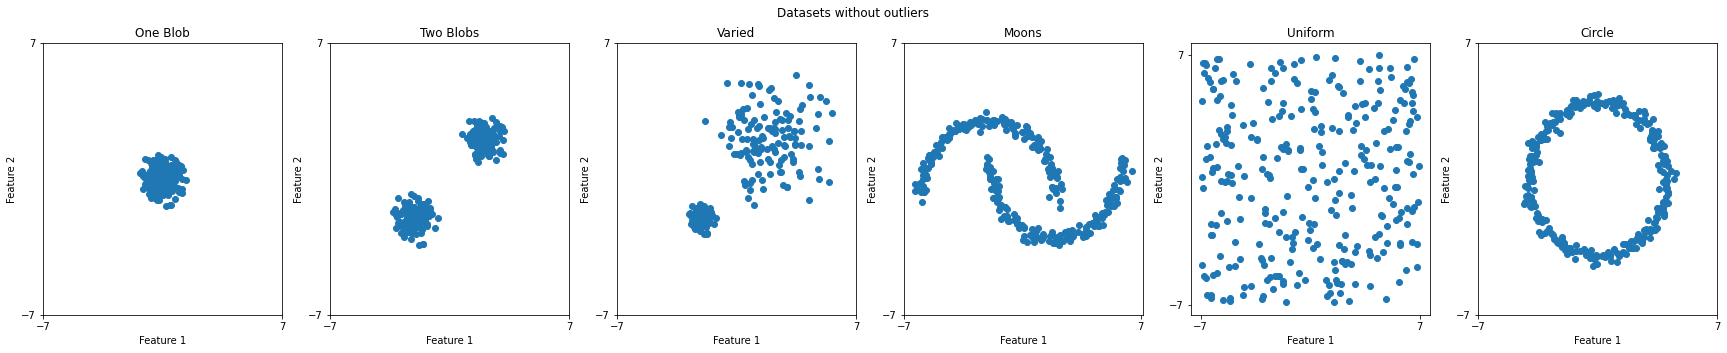

In [4]:
plt.figure(figsize=(30, 5))
plt.suptitle('Datasets without outliers')

for i, dataset in enumerate(datasets):
    plt.subplot(1, len(datasets), i + 1)
    plt.scatter(dataset[:, 0], dataset[:, 1])
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.xticks([-7, 7])
    plt.yticks([-7, 7])
    plt.title(titles[i])

### Визуелизација на податочните множества со додадени отпадници
Отпадниците се додаваат со униформна распределба во опсегот [-6, 6] за двете карактеристики.

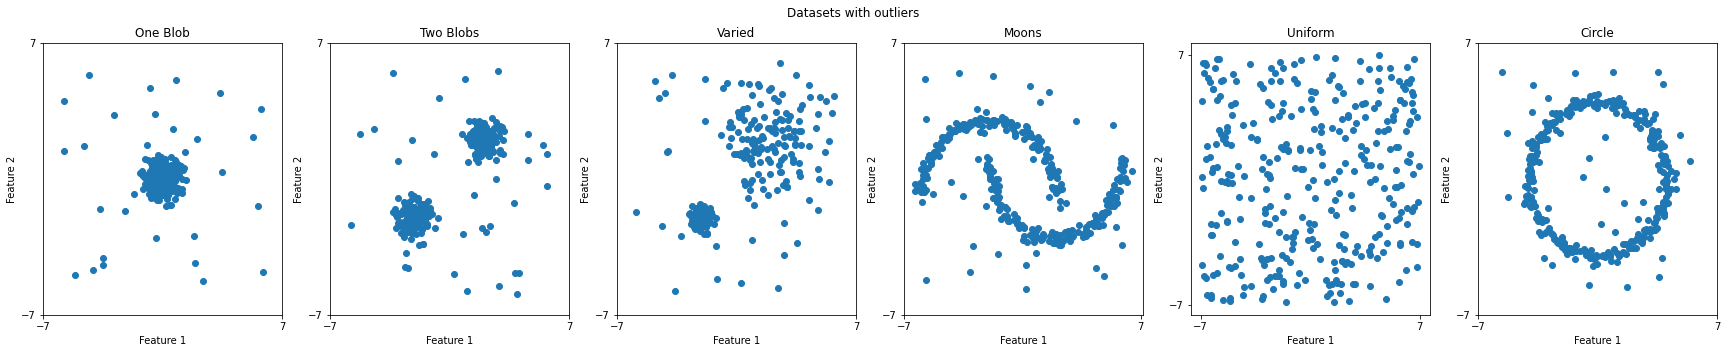

In [5]:
# Add outliers
plt.figure(figsize=(30, 5))
plt.suptitle('Datasets with outliers')
rng = np.random.RandomState(0)
for i, dataset in enumerate(datasets):
    dataset= np.concatenate([datasets[i], rng.uniform(low=-6, high=6, size=(n_outliers, 2))], axis=0)
    plt.subplot(1, len(datasets), i + 1)
    plt. scatter(dataset[:, 0], dataset[:, 1])
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.xticks([-7, 7])
    plt.yticks([-7, 7])
    plt.title(titles[i])

### Тренирање на алгоритми за детекција на аномалии
1. **EllipticEnvelope**
Клучни параметри:
    * **contamination:** сооднос на на бројот на отпадници наспрема вкупниот број на податоци. Доколку не се познава оваа вредност тогаш се проценува според проблемот.
    * **random_state:** семе за случајна иницијализација
    
Овој алгоритам моделира повеќевеличинска гаусова распределба врз множеството за тренирање. Потоа, врз основа на параметарот **contamination** го наоѓа прагот на одлучување за тоа што ќе се смета како отпадник. Прагот на одлучување се наоѓа така што се бира густина на веројатнот под чија вредност припаѓаат толку податочни точки колку што се определени од параметарот **contamination**.

|Предности|Недостатоци|
|---|---|
|Едноставен за имплементација|Не може да наоѓа отпадници кај податочни множества со комплексни форми|
|Брзо се тренира|Границата на одлучување претставува една N-димензионална затворена крива|

2. **Isolation Forest**
Клучни параметри:
    * **contamination:** сооднос на на бројот на отпадници наспрема вкупниот број на податоци. Доколку не се познава оваа вредност тогаш се проценува според проблемот.
    * **n_estimators:** број на дрва. Поголем број на дрва може подобар резултат да даде.
    * **random_state:** семе за случајна иницијализација

Овој алгоритам функционира така што по случаен избор селектира карактеристика и множеството го поделува така што случајно избира граница на поделба помеѓу максималната и минималната вредност на таа карактеристика.

Оваа поделба на податочното множество се повторува рекурзивно за различни карактеристики и граници на поделба. Овој процес генерира дрво каде што секоја поделба се грани на две гранки, а секој лист на дрвото содржи примероци од податочното множество. Кога ова ќе се реализира за n вакви различни дрва, ќе се добие модел каде што отпадници најчесто ќе се најдат во листови кои се поблиску до коренот на дрвото.

|Предности|Недостатоци|
|---|---|
|Границата на одлучување може да опфаќа повеќе комплексни затворени криви|Содржи повеќе параметри за нагодување|
||Побавно се тренира|


In [6]:
anomaly_algorithms = {'EllipticEnvelope': EllipticEnvelope(contamination=outliers_fraction, random_state=0), 
                      'IsolationForest': IsolationForest(contamination=outliers_fraction, random_state=0, n_estimators=100)}

### Визуелизација на податочните множество заедно со границата на поделба

1. Отпадниците се обележани со сина боја, а обичните податоци со портокалова
2. Гранциата на поделба е прикажана со црна боја
3. Алгоритмите се тренирани на целото податочно множество, заедно со аномалиите

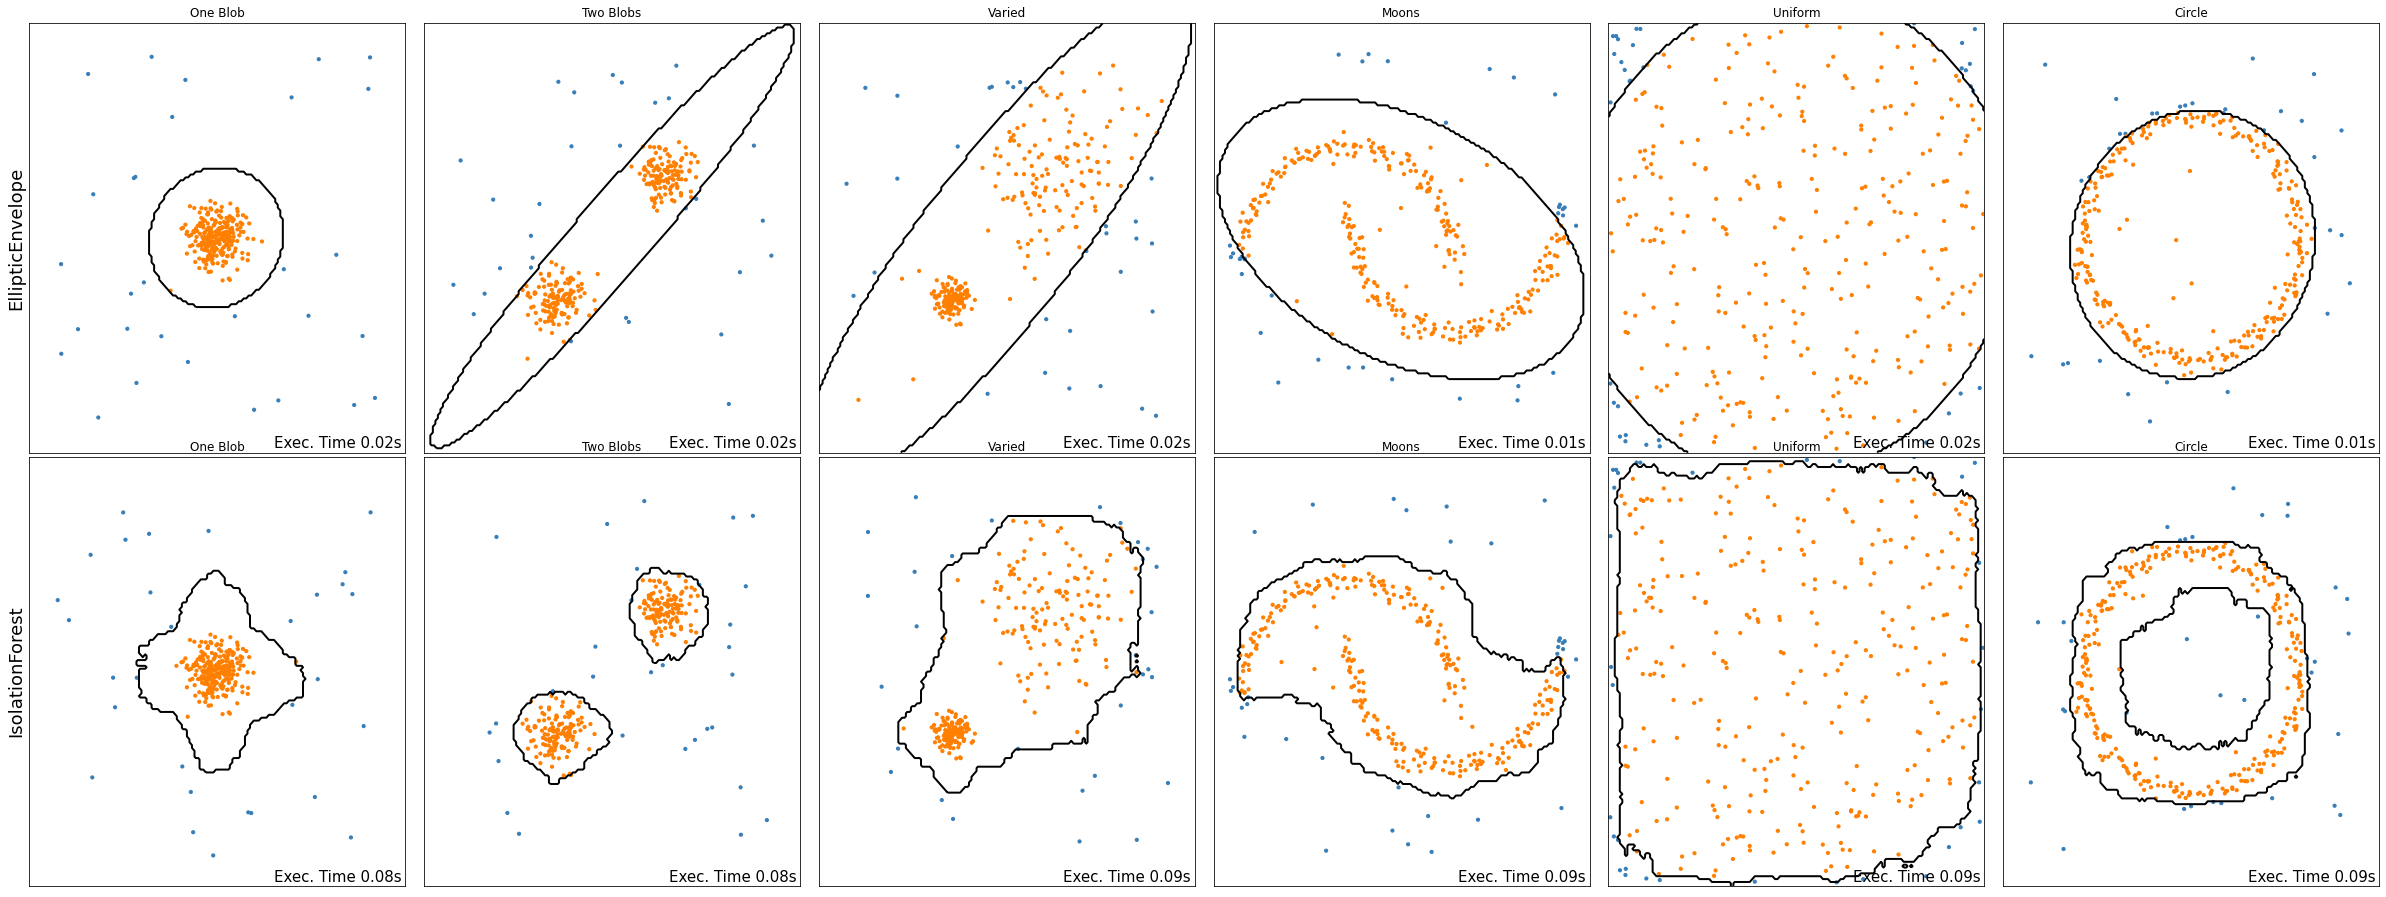

In [7]:
# Compare given classifiers under given settings
xx, yy = np.meshgrid(np.linspace(-7, 7, 150),
                     np.linspace(-7, 7, 150))

plt.figure(figsize=(len(anomaly_algorithms) * 2 + 30, 12.5))
plt.subplots_adjust(left=.02, right=.98, bottom=.001, top=.96, wspace=.05,
                    hspace=.01)

plot_num = 1



for name, algorithm in anomaly_algorithms.items():
    for i_dataset, X in enumerate(datasets):
        # Add outliers
        X = np.concatenate([X, rng.uniform(low=-6, high=6,
                           size=(n_outliers, 2))], axis=0)
        
        t0 = time.time()
        algorithm.fit(X)
        t1 = time.time()
        plt.subplot(len(anomaly_algorithms), len(datasets), plot_num)

        if i_dataset == 0:
            plt.ylabel(name, size=18)
        
        y_pred = algorithm.predict(X)
        colors = np.array(['#377eb8', '#ff7f00'])
        plt.scatter(X[:, 0], X[:, 1], s=10, color=colors[(y_pred + 1) // 2])
        
        Z = algorithm.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        plt.contour(xx, yy, Z, levels=[0], linewidths=2, colors='black')
            
        plt.xlim(-7, 7)
        plt.ylim(-7, 7)
        plt.xticks(())
        plt.yticks(())
        plt.text(.99, .01, ('Exec. Time %.2fs' % (t1 - t0)).lstrip('0'),
                 transform=plt.gca().transAxes, size=15,
                 horizontalalignment='right')
        plot_num += 1
        plt.title(titles[i_dataset])

plt.show()

# Детекција на аномалии при работа на тест машина составена од електромотор, осовина и лагери

Ова податочно множество е генерирано од NSF I/UCR [Центар за интелигентно одржување на системи](www.imscenter.net).

Податоците се добиени од тест машина каде што осовина е монтирана на четири лагери. Осовината е придвижувана од електромотор спрегната со каиш и таа врти со константна ротациона брзина од 2000RPM. Осовината е изложена на постојан вртлив товар од 2700kg преку механизам на пружина. Лагерите се производство на фирмата Rexnord од тип ZA-2115 и тие се поставени како што е прикажано во долната слика.

![Приказ на машината](IMSBearingData.jpg)

Податочното множество е составено од три подмножества:

1. **Податочно множество 1**

* Период на мерење: 22.10.2003 12:06:24 - 25.11.2003 23:39:56
* Број на датотеки: 2.156
* Број на карактеристики: 8
* Распределба на карактеристики: карактеристика 1 и 2 за лагер 1, карактеристика 3 и 4 за лагер 2, карактеристика 5 и 6 за лагер 3, карактеристика 7 и 8 за лагер 4
* Интервал на мерење: На секои 10 минути. Со исклучок на првите 43 датотеки каде мерењето се извршува на секои 5 минути
* Формат на датотека: ASCII
* Опис: На крајот при појава на дефектот, проблемот е предизвикан кај лагер 3 и 4

2. **Податочно множество 2**

* Период на мерење: 12.02.2004 10:32:39 - 19.02.2004 06:22:39
* Број на датотеки: 984
* Број на карактеристики: 4
* Распределба на карактеристики: карактеристика 1 за лагер 1, карактеристика 2 за лагер 2, карактеристика 3 за лагер 3, карактеристика 4 за лагер 4
* Интервал на мерење: На секои 10 минути
* Формат на датотека: ASCII
* Опис: На крајот при појава на дефектот, проблемот е предизвикан кај лагер 1

3. **Податочно множество 3**

* Период на мерење: 04.03.2004 09:27:46 - 04.04.2004 19:01:57
* Број на датотеки: 4448
* Број на карактеристики: 4
* Распределба на карактеристики: карактеристика 1 за лагер 1, карактеристика 2 за лагер 2, карактеристика 3 за лагер 3, карактеристика 4 за лагер 4
* Интервал на мерење: На секои 10 минути
* Формат на датотека: ASCII
* Опис: На крајот при појава на дефектот, проблемот е предизвикан кај лагер 3


Акцелерометри со висока сензитивност Quarts ICP се монтирани на секое куќиште од лагерите. Конкретно, распределени се по два акцелерометри за секој лагер по x и y оска во податочно множество 1, еден акцелерометар за секој лагер во податочно множество 2 и 3. Поставеноста на сензорите е исто така прикажана во сликата. Сите механички потфрлувања на лагерите се настанати после надминување на предвидениот живот на работа кој е предвиден над 100 милиони револуции. За повеќе информации прочитајте го „Readme Document for IMS Bearing Data.pdf".

### Вчитување на библиотеки

In [8]:
import os
import seaborn as sns

## Симнување на податоците
Податоците се состојат од повеќе множества, но ние ќе работиме само со второто од нив. Од оваа [врска](https://feitukimedumk-my.sharepoint.com/:u:/g/personal/fdoncevski_feit_ukim_edu_mk/EfYgnuWasQhJntaUsR7tTJ8BmHrLukwfwmALxGRAGTv6Jg?e=oBFOcG) симнете го второто податочно множество.

## Отпакување на податоците
Отпакувајте ги податоците во соодветен директориум под име BearingDataSet/2nd Test.

## Вчитување на податоците
Една датотека од податочното множество содржи мерења во период од ~1 секунда со време на семплирање од 20kHz. Поради тоа секоја датотека содржи ~20000 редици. Ние ќе направиме агрегација на една временска рамка и ќе ја претставиме како една податочка точка така што ќе ја пресметаме средната вредност на забрзувањата за секој лагер.

### Изминување на секоја датотека од податочното множество, наоѓање на средна вредност и сместување на истата во табела merged_data
Резултатите се запишуваат во 'merged_dataset_BearingTest_2.csv'.

In [9]:
data_dir = 'BearingDataSet\\2nd_test'
merged_data = pd.DataFrame()

for filename in os.listdir(data_dir):
    dataset=pd.read_csv(os.path.join(data_dir, filename), sep='\t')
    dataset_mean_abs = np.array(dataset.abs().mean())
    dataset_mean_abs = pd.DataFrame(dataset_mean_abs.reshape(1,4))
    dataset_mean_abs.index = [filename]
    merged_data = merged_data.append(dataset_mean_abs)

merged_data.columns = ['Bearing_1','Bearing_2','Bearing_3','Bearing_4']
merged_data.index = pd.to_datetime(merged_data.index, format='%Y.%m.%d.%H.%M.%S')
merged_data = merged_data.sort_index()
merged_data.to_csv('merged_dataset_BearingTest_2.csv')

### Прикажете општи информации за податочното множество
Операциите да се извршат врз merged_data табелата.

**помош: head(), info(), describe(), .columns**

In [10]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 984 entries, 2004-02-12 10:32:39 to 2004-02-19 06:22:39
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Bearing_1  984 non-null    float64
 1   Bearing_2  984 non-null    float64
 2   Bearing_3  984 non-null    float64
 3   Bearing_4  984 non-null    float64
dtypes: float64(4)
memory usage: 38.4 KB


In [11]:
merged_data.describe()

,Bearing_1,Bearing_2,Bearing_3,Bearing_4
count,984.000000,984.000000,984.000000,984.000000
mean,0.080905,0.078532,0.081356,0.047822
std,0.040171,0.011779,0.011596,0.009541
min,0.001168,0.000767,0.000716,0.001699
25%,0.060765,0.074233,0.076832,0.043950
50%,0.062007,0.075203,0.078197,0.044524
75%,0.083223,0.077456,0.080600,0.048111
max,0.453335,0.161016,0.151299,0.119047


## Истражување и визуелизација на податочното множество
### Визуелизирајте ги податоците за секој лагер во зависност од времето
**помош: pyplot.plot()**

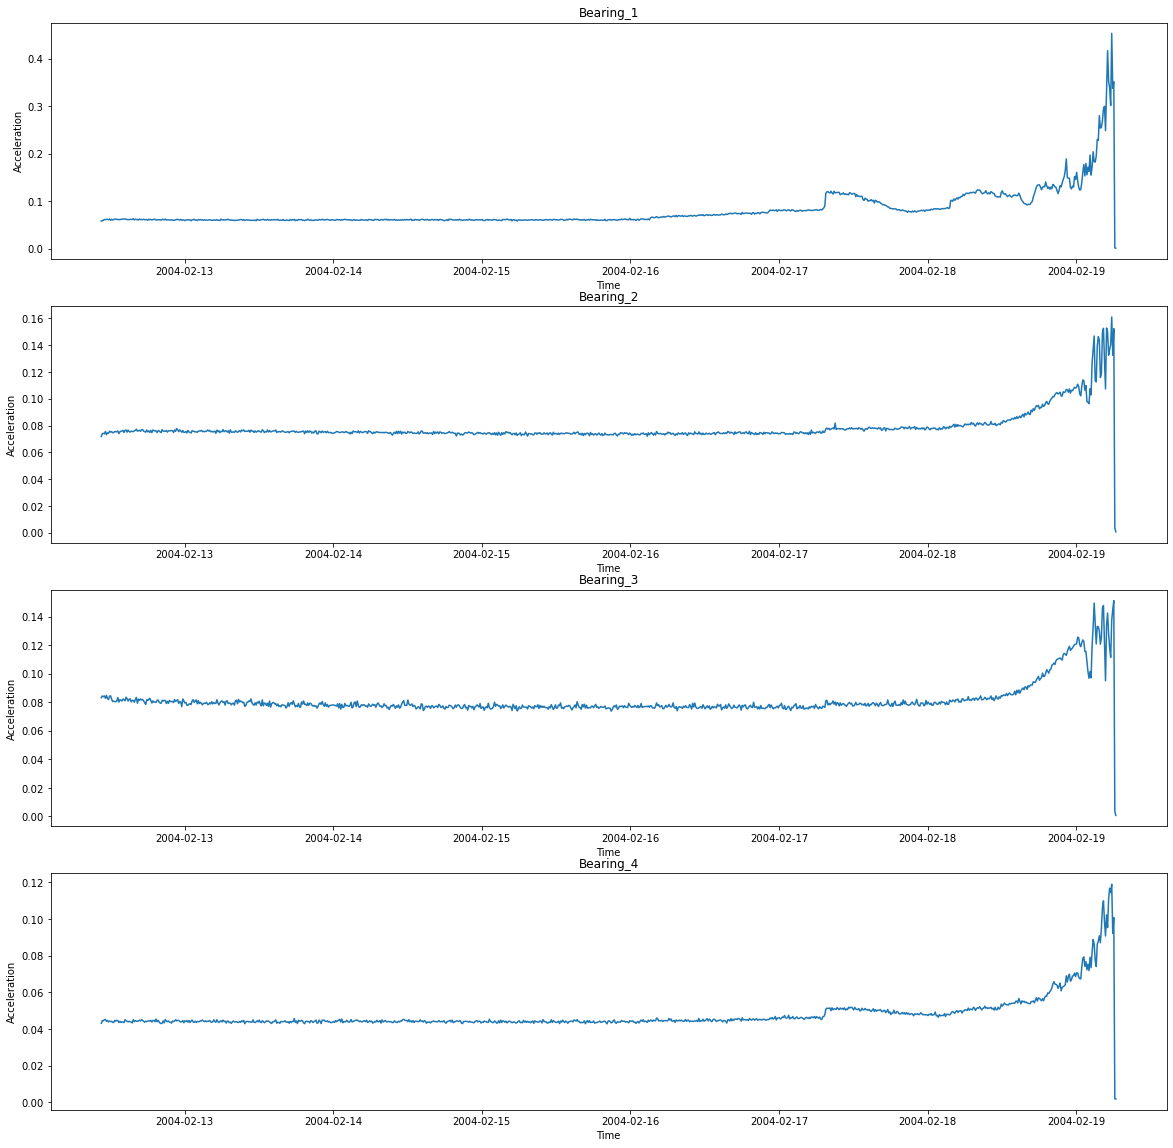

In [12]:
plt.figure(figsize=(20, 20))
for i, column in enumerate(merged_data.columns):
    plt.subplot(len(merged_data.columns), 1, i + 1)
    plt.plot(merged_data[f'Bearing_{i + 1}'])
    plt.xlabel('Time')
    plt.ylabel('Acceleration')
    plt.title(column)

### Применете ја seaborn.pairplot() функцијата врз податочното множество
Воочете дали има точки кои драстично отстапуваат. Тоа ќе ни даде информација дали би било лесно да детектираат истите.

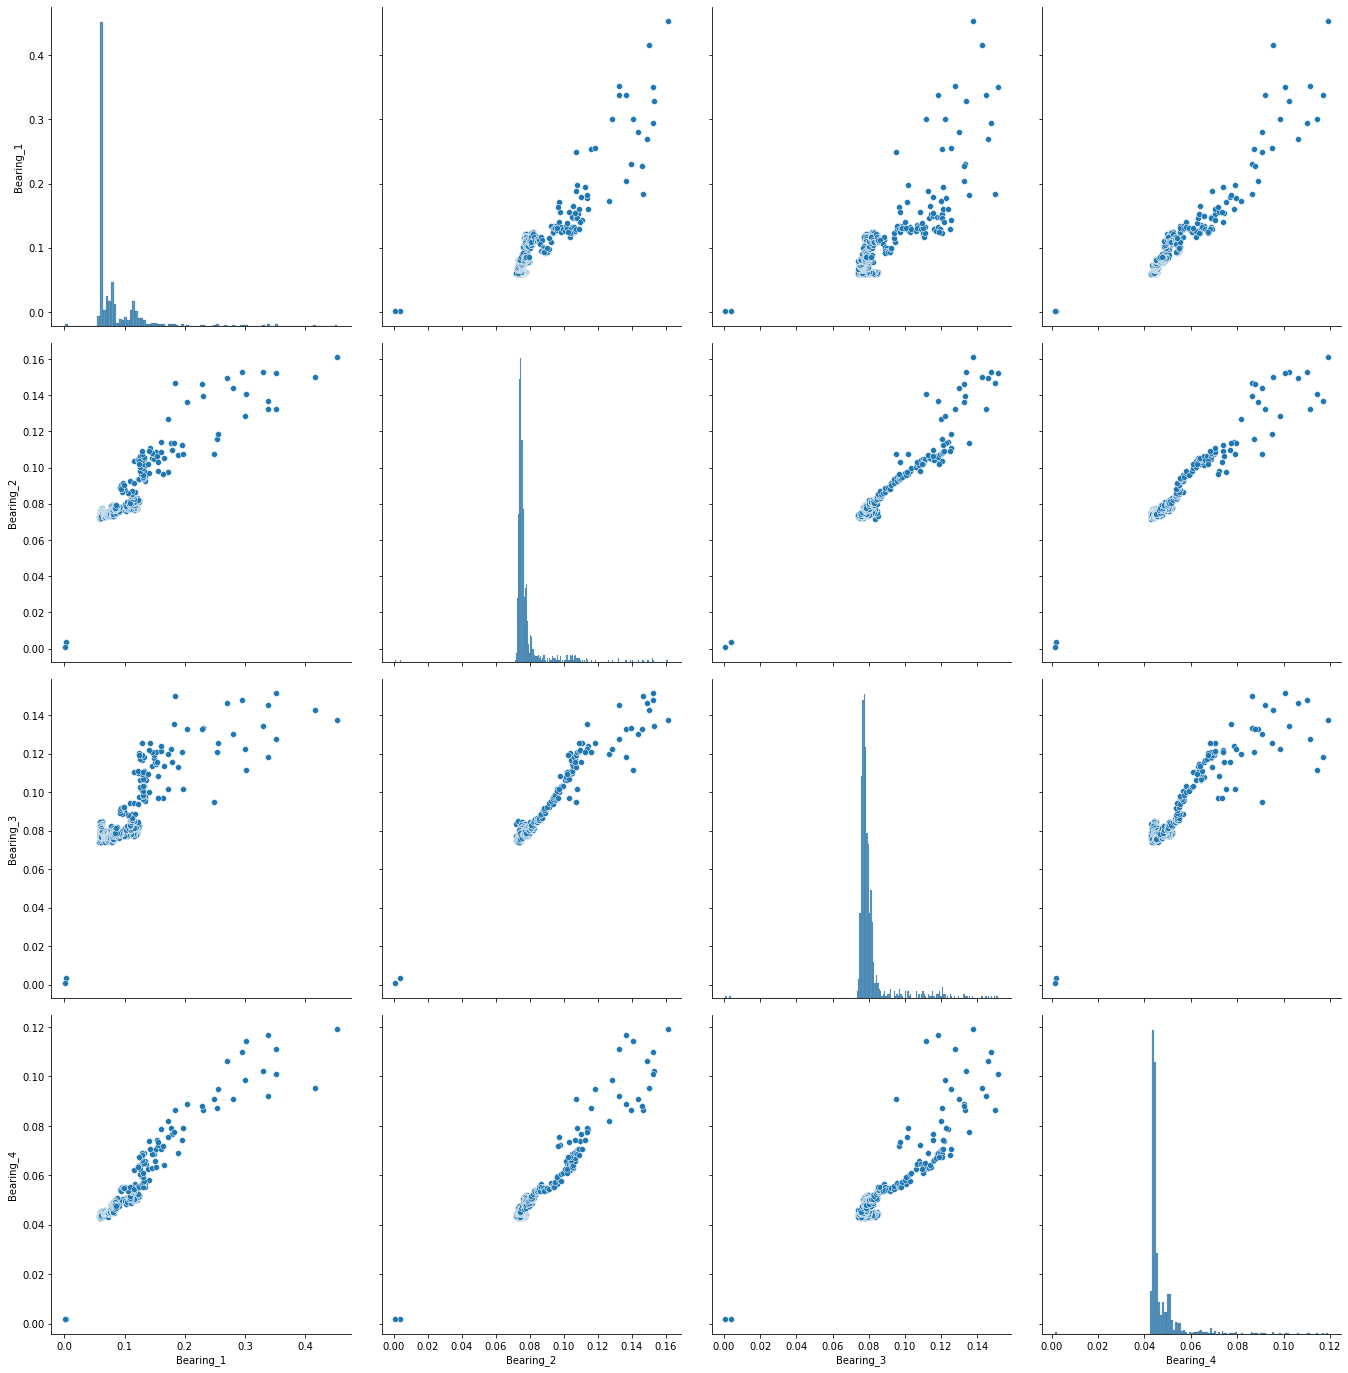

In [13]:
g = sns.pairplot(data=merged_data)
g.fig.set_size_inches(20, 20)

При впарена визуелизација за карактеристиките на секој лагер може да се забележи дека определени податочни точки очигледно отстапуваат драстично од другите. Според тоа можеме да заклучиме дека алгоритамот за детекција на аномалии би требало да даде добри резултати.

## Развој на EllipticEnvelope модел

### Дефинирајте EllipticEnvelope модел за следните параметри: contamination=0.05, random_state=0
**помош: EllipticEnvelope()**

In [14]:
model = EllipticEnvelope(contamination=0.2, random_state=0)

### Истренирајте го моделот на податочното множество
**помош: EllipticEnvelope.*.fit()**

In [15]:
model.fit(merged_data)

EllipticEnvelope(contamination=0.2, random_state=0)

### Додадете нова колона под име "Anomaly" во постоечкота табела merged_data каде ќе ги сместите резултатите од предвидувањето
**помош: EllipticEnvelope.*.predict()**

In [16]:
merged_data['Anomaly'] = model.predict(merged_data)

### Применете ја seaborn.pairplot() функцијата врз новата табела и воочете ги детектираните аномалии
**помош: seaborn.pairplot(hue='Anomaly', palette='tab10'); Со -1 се обележуваат отпадници**

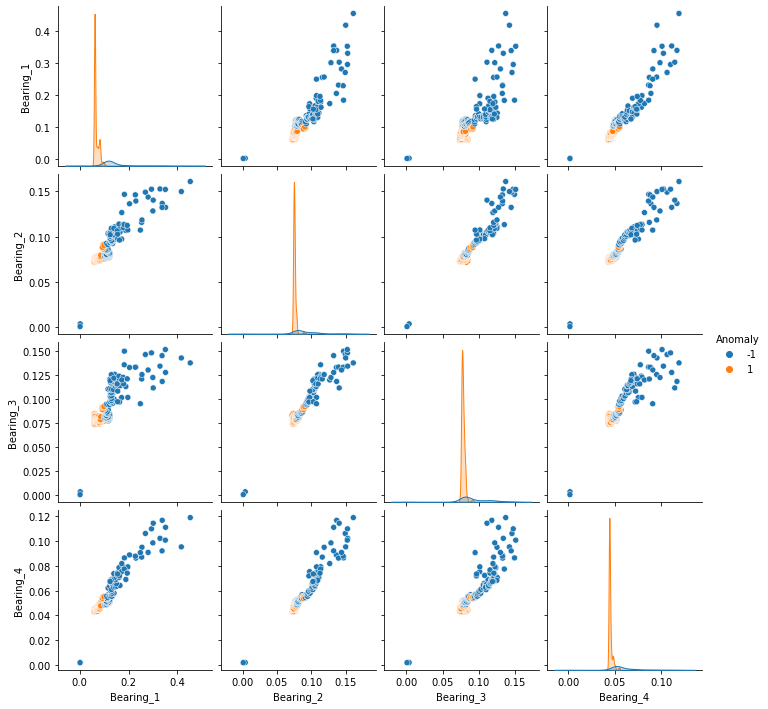

In [17]:
sns.pairplot(data=merged_data, hue='Anomaly', palette = "tab10")

### Исцртајте ги на график сите колони заедно и забележете го моментот кога се детектираат аномалиите

<AxesSubplot:>

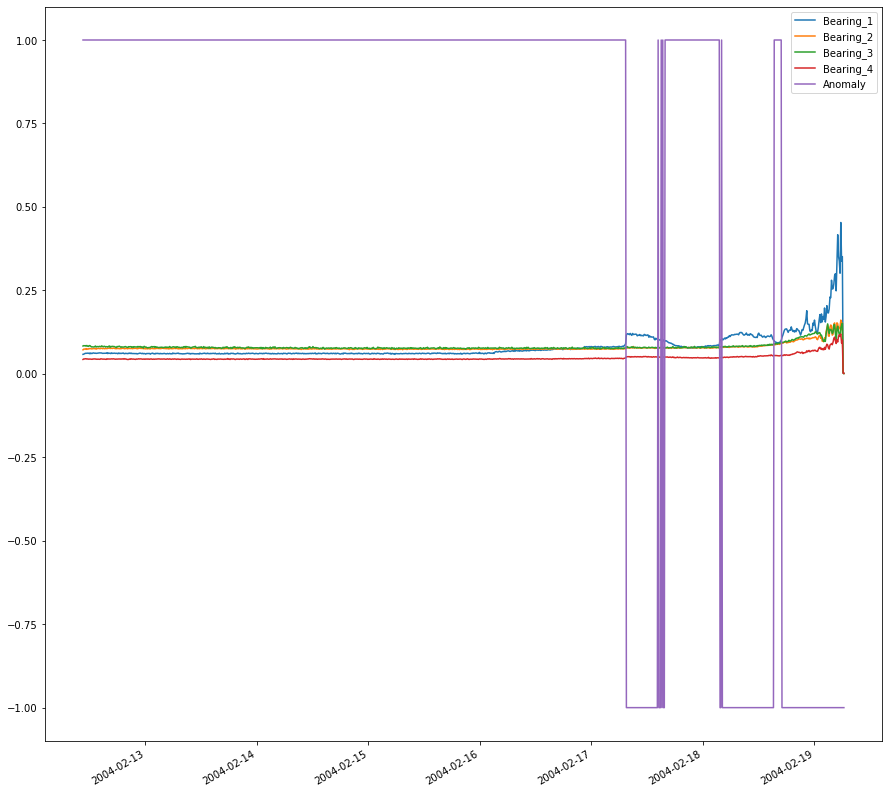

In [18]:
merged_data.plot(figsize=(15, 15))

In [19]:
print('Дефектот се детектира за:', merged_data.index[-1] - merged_data[merged_data['Anomaly'] == -1].index[0], "порано")

Дефектот се детектира за: 1 days 22:50:00 порано


Забележете дека детекцијата на дефектот не перманентна туку таа транзитира помеѓу нормална работа и дефект, во зависност од измерените сигнали. Ова може да се подобри доколку се нагоди параметарот contamination.